# Customer Purchase Behavior Analysis & Data Preprocessing

## 1. Project Planning & Problem Framing

### What is Data Analysis?
Data Analysis is the process of collecting, cleaning, transforming and examining data to find useful information and make better decisions.

### Steps in a Data Science Project
1. Data Collection
2. Data Understanding
3. Data Cleaning
4. Exploratory Data Analysis
5. Feature Engineering
6. Model Building
7. Model Evaluation

### Problem Statement
The objective of this project is to analyze customer purchase behavior and understand customer spending patterns.

The project focuses on data preprocessing and feature engineering to prepare data for future machine learning applications.

### Project Objectives
- Analyze customer demographic information.
- Understand customer transaction behavior.
- Analyze product categories and prices.
- Identify spending patterns.
- Handle missing values and outliers.
- Perform categorical encoding.
- Apply feature scaling.
- Create meaningful customer-level features.

## 2. Data Import & Understanding

Data collection is the first step of data analysis.

In this step, we collect data from different sources and load it into Python using appropriate libraries.

### Data Sources
1. CSV – Customer information.
2. JSON – Transaction information.
3. SQL – Product information.

### Libraries Used
- Pandas
- NumPy
- JSON
- SQLite3
- Matplotlib
- Seaborn

After loading the datasets, we will examine their structure and understand the available columns.

In [1]:
import pandas as pd
import numpy as np
import json
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
customers_df = pd.read_csv('../Data/customers.csv')
print("Customers Dataset Loaded Successfully")
display(customers_df.head())

Customers Dataset Loaded Successfully


,customer_id,name,age,gender,city,income
0,101,Aarav,24,Male,Mumbai,45000
1,102,Diya,30,Female,Delhi,55000
2,103,Kabir,27,Male,Bangalore,48000
3,104,Meera,35,Female,Ahmedabad,60000
4,105,Vivaan,40,Male,Pune,75000


In [4]:
with open('../Data/transactions.json','r') as file:
    transactions_data = json.load(file)
transactions_df = pd.DataFrame(transactions_data)
print("Transactions Dataset Loaded Successfully")
display(transactions_df.head())

Transactions Dataset Loaded Successfully


,transaction_id,customer_id,product_id,amount,payment_mode,date
0,T001,101,P001,499,UPI,2025-10-01
1,T002,103,P003,1299,Credit Card,2025-10-02
2,T003,104,P002,699,Debit Card,2025-10-03
3,T004,105,P005,1999,UPI,2025-10-05
4,T005,107,P004,899,Cash,2025-10-07


In [5]:
connection = sqlite3.connect(':memory:')
with open('../Data/products.sql','r') as file:
    sql_script = file.read()
connection.executescript(sql_script)
products_df = pd.read_sql_query("SELECT * FROM products",connection)
print("Products Dataset Loaded Successfully")
display(products_df.head())

Products Dataset Loaded Successfully


,product_id,product_name,category,price,stock
0,P001,Earphones,Electronics,499,50
1,P002,Bluetooth Speaker,Audio,699,40
2,P003,Smart Watch,Wearable,1299,25
3,P004,Keyboard,Computer,899,60
4,P005,Headphones,Audio,1999,30


### API Data Fetching

API (Application Programming Interface) allows us to collect data from external sources.

In this project, we use the DummyJSON Users API to fetch user information.

API URL: https://dummyjson.com/users

We use the Python Requests library to send a GET request and retrieve data in JSON format.

In [62]:
import requests
url = "https://dummyjson.com/users"
response = requests.get(url,params={"limit":0},timeout=30)
response.raise_for_status()
api_data = response.json()
api_users_df = pd.json_normalize(api_data['users'])
print("API Data Fetched Successfully!")
print("Total Users:",len(api_users_df))
print("Dataset Shape:",api_users_df.shape)
display(api_users_df)

API Data Fetched Successfully!
Total Users: 208
Dataset Shape: (208, 52)


,id,firstName,lastName,maidenName,age,gender,email,phone,username,password,...,company.address.city,company.address.state,company.address.stateCode,company.address.postalCode,company.address.coordinates.lat,company.address.coordinates.lng,company.address.country,crypto.coin,crypto.wallet,crypto.network
0,1,Emily,Johnson,Smith,29,female,emily.johnson@x.dummyjson.com,+81 965-431-3024,emilys,emilyspass,...,San Francisco,Wisconsin,WI,37657,71.814525,-161.150263,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
1,2,Michael,Williams,,36,male,michael.williams@x.dummyjson.com,+49 258-627-6644,michaelw,michaelwpass,...,Los Angeles,New Hampshire,NH,73442,79.098326,-119.624845,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
2,3,Sophia,Brown,,43,female,sophia.brown@x.dummyjson.com,+81 210-652-2785,sophiab,sophiabpass,...,Dallas,Nevada,NV,88511,20.086743,-34.577107,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
3,4,James,Davis,,46,male,james.davis@x.dummyjson.com,+49 614-958-9364,jamesd,jamesdpass,...,Fort Worth,Pennsylvania,PA,27768,54.911930,-79.498328,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
4,5,Emma,Miller,Johnson,31,female,emma.miller@x.dummyjson.com,+91 759-776-1614,emmaj,emmajpass,...,San Antonio,Idaho,ID,21965,44.346545,-26.944701,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,204,Mateo,Perez,,46,male,mateo.perez@x.dummyjson.com,+44 704-302-8113,mateop,mateoppass,...,Denver,Arizona,AZ,10591,18.569908,-50.337520,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
204,205,Aubrey,Garcia,Gray,29,female,aubrey.garcia@x.dummyjson.com,+1 470-576-9130,aubreyg,aubreygpass,...,San Francisco,Minnesota,MN,58649,3.609112,-35.397672,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
205,206,Elena,Baker,,35,female,elena.baker@x.dummyjson.com,+49 978-346-6960,elenab,elenabpass,...,San Antonio,Idaho,ID,50546,1.356153,175.897893,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)
206,207,Jace,Smith,,42,male,jace.smith@x.dummyjson.com,+1 634-923-7779,jaces,jacespass,...,San Francisco,Arizona,AZ,19079,2.230209,84.272010,United States,Bitcoin,0xb9fc2fe63b2a6c003f1c324c3bfa53259162181a,Ethereum (ERC20)


In [6]:
print("CUSTOMERS INFORMATION")
customers_df.info()
print("\nTRANSACTIONS INFORMATION")
transactions_df.info()
print("\nPRODUCTS INFORMATION")
products_df.info()

CUSTOMERS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  8 non-null      int64 
 1   name         8 non-null      object
 2   age          8 non-null      int64 
 3   gender       8 non-null      object
 4   city         8 non-null      object
 5   income       8 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 516.0+ bytes

TRANSACTIONS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  8 non-null      object
 1   customer_id     8 non-null      int64 
 2   product_id      8 non-null      object
 3   amount          8 non-null      int64 
 4   payment_mode    8 non-null      object
 5   date            8 non-null      object
dtypes: int64(2),

In [7]:
print("CUSTOMERS INFORMATION")
customers_df.info()
print("\nTRANSACTIONS INFORMATION")
transactions_df.info()
print("\nPRODUCTS INFORMATION")
products_df.info()

CUSTOMERS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  8 non-null      int64 
 1   name         8 non-null      object
 2   age          8 non-null      int64 
 3   gender       8 non-null      object
 4   city         8 non-null      object
 5   income       8 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 516.0+ bytes

TRANSACTIONS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  8 non-null      object
 1   customer_id     8 non-null      int64 
 2   product_id      8 non-null      object
 3   amount          8 non-null      int64 
 4   payment_mode    8 non-null      object
 5   date            8 non-null      object
dtypes: int64(2),

In [8]:
print("Customers Shape:",customers_df.shape)
print("Transactions Shape:",transactions_df.shape)
print("Products Shape:",products_df.shape)

Customers Shape: (8, 6)
Transactions Shape: (8, 6)
Products Shape: (6, 5)


### Observation

- Customer dataset contains 8 records and 6 columns.
- Transaction dataset contains 8 records and 6 columns.
- Product dataset contains 6 records and 5 columns.
- Customer information is loaded from CSV.
- Transaction information is loaded from JSON.
- Product information is loaded from SQL database.

All three datasets are successfully loaded into Pandas DataFrames.

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the structure, distribution, patterns and relationships present in the dataset.

EDA is divided into three main types:

1. Univariate Analysis
2. Bivariate Analysis
3. Multivariate Analysis

### 3.1 Univariate Analysis

Univariate analysis examines one variable at a time.

It helps understand the distribution and frequency of individual variables.

Techniques:
- Histogram
- Boxplot
- Skewness
- Frequency Distribution

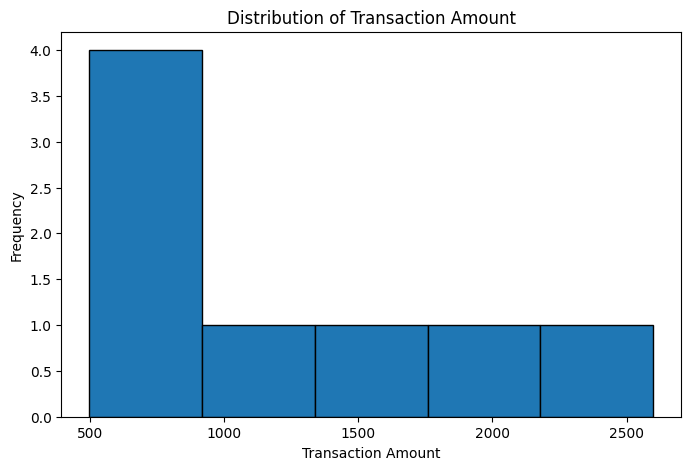

In [9]:
plt.figure(figsize=(8,5))
plt.hist(transactions_df['amount'],bins=5,edgecolor='black')
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

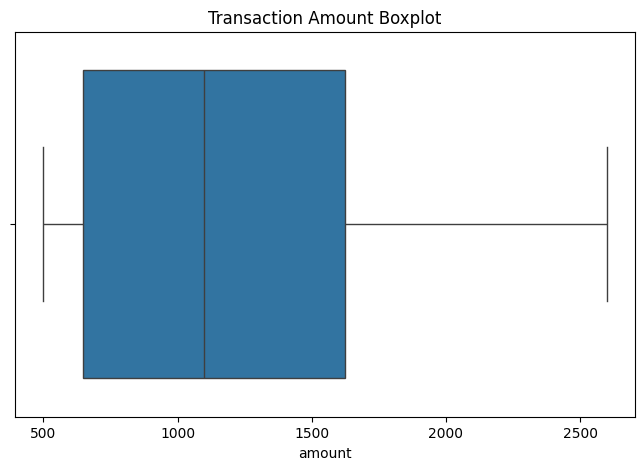

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x=transactions_df['amount'])
plt.title("Transaction Amount Boxplot")
plt.show()

In [11]:
print("Amount Skewness:",transactions_df['amount'].skew())

Amount Skewness: 0.8135685281523616


In [12]:
print(transactions_df['payment_mode'].value_counts())

payment_mode
UPI            3
Credit Card    2
Cash           2
Debit Card     1
Name: count, dtype: int64


### 3.2 Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

It helps identify how one variable changes with another variable.

Techniques:
- Correlation Analysis
- Grouped Mean
- Category-wise Comparison

payment_mode
Cash            699.0
Credit Card    1399.0
Debit Card      699.0
UPI            1699.0
Name: amount, dtype: float64

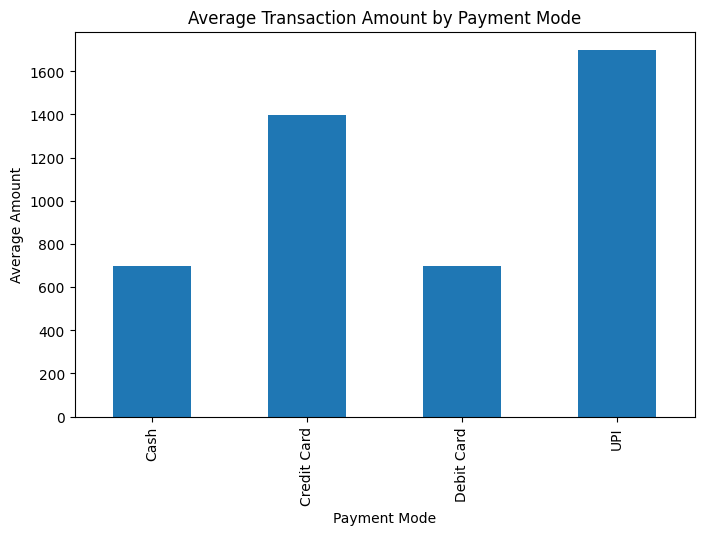

In [13]:
payment_analysis = transactions_df.groupby('payment_mode')['amount'].mean()
display(payment_analysis)
payment_analysis.plot(kind='bar',figsize=(8,5))
plt.title("Average Transaction Amount by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Average Amount")
plt.show()

### 3.3 Multivariate Analysis

Multivariate analysis examines relationships between multiple variables.

Techniques:
- Pairplot
- Correlation Heatmap
- Grouped Statistics

In [14]:
merged_df = transactions_df.merge(customers_df,on='customer_id',how='left')
merged_df = merged_df.merge(products_df,on='product_id',how='left')
display(merged_df.head())

,transaction_id,customer_id,product_id,amount,payment_mode,date,name,age,gender,city,income,product_name,category,price,stock
0,T001,101,P001,499,UPI,2025-10-01,Aarav,24,Male,Mumbai,45000,Earphones,Electronics,499,50
1,T002,103,P003,1299,Credit Card,2025-10-02,Kabir,27,Male,Bangalore,48000,Smart Watch,Wearable,1299,25
2,T003,104,P002,699,Debit Card,2025-10-03,Meera,35,Female,Ahmedabad,60000,Bluetooth Speaker,Audio,699,40
3,T004,105,P005,1999,UPI,2025-10-05,Vivaan,40,Male,Pune,75000,Headphones,Audio,1999,30
4,T005,107,P004,899,Cash,2025-10-07,Aryan,29,Male,Kolkata,50000,Keyboard,Computer,899,60


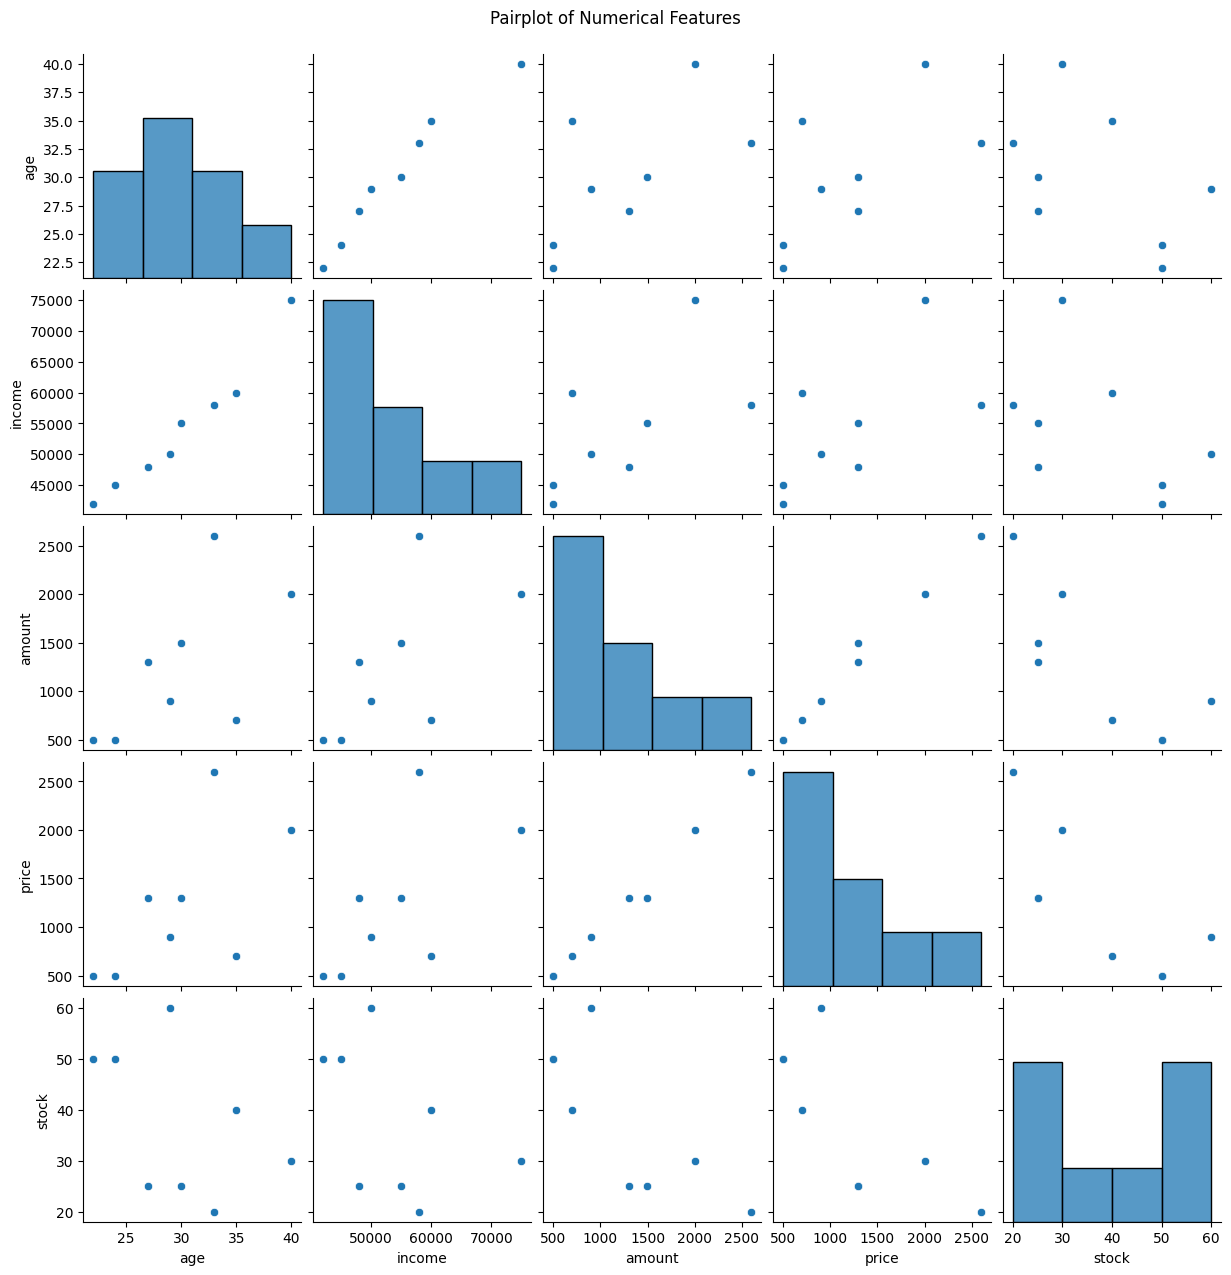

In [60]:
sns.pairplot(merged_df[['age','income','amount','price','stock']])
plt.suptitle("Pairplot of Numerical Features",y=1.02)
plt.show()

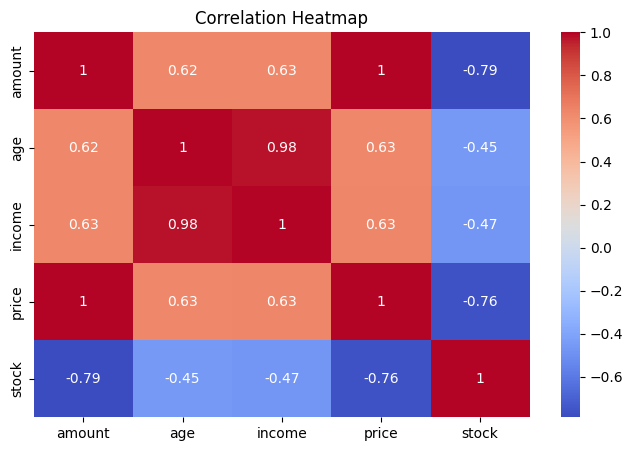

In [16]:
plt.figure(figsize=(8,5))
sns.heatmap(merged_df[['amount','age','income','price','stock']].corr(),annot=True,cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [17]:
display(merged_df.groupby('category')['amount'].agg(['mean','sum','count']))

,mean,sum,count
category,,,
Audio,1349.0,2698,2
Computer,899.0,899,1
Electronics,499.0,998,2
Mobile Accessories,2599.0,2599,1
Wearable,1399.0,2798,2


### 4. Handling Missing Data

Missing data refers to values that are not available in a dataset.

Missing values can affect data analysis and model performance. Therefore, we identify and handle missing values using suitable techniques.

Common techniques:

* Mean Imputation: Replace missing numerical values with the mean.
* Median Imputation: Replace missing numerical values with the median.
* Mode Imputation: Replace missing categorical values with the most frequent value.
* Dropping: Remove rows or columns containing missing values when appropriate.

In our original datasets, no missing values were found. Therefore, a temporary dataset is created to demonstrate missing value handling techniques.


In [18]:
print("Customers Missing Values:")
print(customers_df.isnull().sum())
print("\nTransactions Missing Values:")
print(transactions_df.isnull().sum())
print("\nProducts Missing Values:")
print(products_df.isnull().sum())

Customers Missing Values:
customer_id    0
name           0
age            0
gender         0
city           0
income         0
dtype: int64

Transactions Missing Values:
transaction_id    0
customer_id       0
product_id        0
amount            0
payment_mode      0
date              0
dtype: int64

Products Missing Values:
product_id      0
product_name    0
category        0
price           0
stock           0
dtype: int64


In [19]:
missing_df = customers_df.copy()
missing_df.loc[0,'age'] = np.nan
missing_df.loc[1,'income'] = np.nan
missing_df.loc[2,'city'] = np.nan
display(missing_df)

,customer_id,name,age,gender,city,income
0,101,Aarav,NaN,Male,Mumbai,45000.0
1,102,Diya,30.0,Female,Delhi,NaN
2,103,Kabir,27.0,Male,NaN,48000.0
3,104,Meera,35.0,Female,Ahmedabad,60000.0
4,105,Vivaan,40.0,Male,Pune,75000.0
5,106,Riya,22.0,Female,Chennai,42000.0
6,107,Aryan,29.0,Male,Kolkata,50000.0
7,108,Isha,33.0,Female,Surat,58000.0


In [20]:
print(missing_df.isnull().sum())

customer_id    0
name           0
age            1
gender         0
city           1
income         1
dtype: int64


In [21]:
missing_df['age'] = missing_df['age'].fillna(missing_df['age'].mean())
display(missing_df)

,customer_id,name,age,gender,city,income
0,101,Aarav,30.857143,Male,Mumbai,45000.0
1,102,Diya,30.000000,Female,Delhi,NaN
2,103,Kabir,27.000000,Male,NaN,48000.0
3,104,Meera,35.000000,Female,Ahmedabad,60000.0
4,105,Vivaan,40.000000,Male,Pune,75000.0
5,106,Riya,22.000000,Female,Chennai,42000.0
6,107,Aryan,29.000000,Male,Kolkata,50000.0
7,108,Isha,33.000000,Female,Surat,58000.0


In [22]:
missing_df['income'] = missing_df['income'].fillna(missing_df['income'].median())
display(missing_df)

,customer_id,name,age,gender,city,income
0,101,Aarav,30.857143,Male,Mumbai,45000.0
1,102,Diya,30.000000,Female,Delhi,50000.0
2,103,Kabir,27.000000,Male,NaN,48000.0
3,104,Meera,35.000000,Female,Ahmedabad,60000.0
4,105,Vivaan,40.000000,Male,Pune,75000.0
5,106,Riya,22.000000,Female,Chennai,42000.0
6,107,Aryan,29.000000,Male,Kolkata,50000.0
7,108,Isha,33.000000,Female,Surat,58000.0


In [23]:
missing_df['city'] = missing_df['city'].fillna(missing_df['city'].mode()[0])
display(missing_df)

,customer_id,name,age,gender,city,income
0,101,Aarav,30.857143,Male,Mumbai,45000.0
1,102,Diya,30.000000,Female,Delhi,50000.0
2,103,Kabir,27.000000,Male,Ahmedabad,48000.0
3,104,Meera,35.000000,Female,Ahmedabad,60000.0
4,105,Vivaan,40.000000,Male,Pune,75000.0
5,106,Riya,22.000000,Female,Chennai,42000.0
6,107,Aryan,29.000000,Male,Kolkata,50000.0
7,108,Isha,33.000000,Female,Surat,58000.0


In [24]:
print("Missing Values After Imputation:")
print(missing_df.isnull().sum())

Missing Values After Imputation:
customer_id    0
name           0
age            0
gender         0
city           0
income         0
dtype: int64


### 5. Outlier Detection and Handling

Outliers are extreme values that are significantly different from other observations in a dataset.

Outliers can affect statistical analysis and machine learning model performance.

Common methods for detecting outliers:
- Boxplot Method
- IQR (Interquartile Range) Method
- Z-Score Method

In this project, we use the IQR method to detect outliers in the transaction amount column.

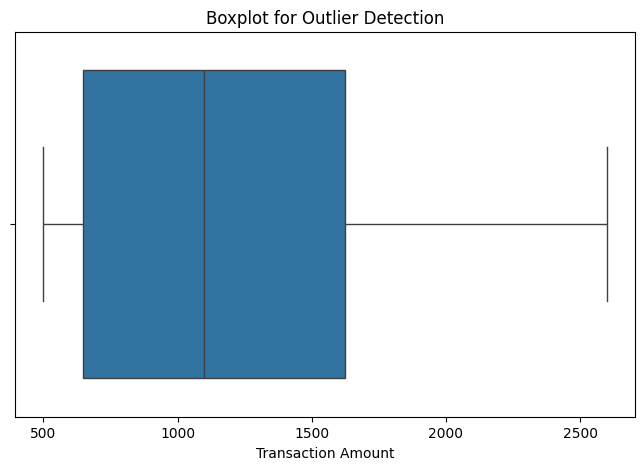

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(x=transactions_df['amount'])
plt.title("Boxplot for Outlier Detection")
plt.xlabel("Transaction Amount")
plt.show()

In [27]:
Q1 = transactions_df['amount'].quantile(0.25)
Q3 = transactions_df['amount'].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Q1: 649.0
Q3: 1624.0
IQR: 975.0
Lower Bound: -813.5
Upper Bound: 3086.5


In [28]:
outliers = transactions_df[(transactions_df['amount']<lower_bound)|(transactions_df['amount']>upper_bound)]
print("Outliers:")
display(outliers)

Outliers:


,transaction_id,customer_id,product_id,amount,payment_mode,date


In [29]:
print("Total Outliers:",len(outliers))

Total Outliers: 0


### Outlier Handling

After detecting outliers, we can handle them using different techniques:

- Removal: Remove extreme values when they are incorrect or irrelevant.
- Capping: Replace extreme values with the lower or upper boundary.
- Transformation: Apply mathematical transformations to reduce the effect of extreme values.

In this project, we use the capping method on a separate copy of the transaction dataset. The original data remains unchanged.

In [30]:
transactions_cleaned = transactions_df.copy()
transactions_cleaned['amount'] = transactions_cleaned['amount'].clip(lower=lower_bound,upper=upper_bound)
display(transactions_cleaned[['transaction_id','amount']])

,transaction_id,amount
0,T001,499
1,T002,1299
2,T003,699
3,T004,1999
4,T005,899
5,T006,2599
6,T007,1499
7,T008,499


In [31]:
print("Original Maximum Amount:",transactions_df['amount'].max())
print("After Capping Maximum Amount:",transactions_cleaned['amount'].max())

Original Maximum Amount: 2599
After Capping Maximum Amount: 2599


### 6. Mixed Data and Date-Time Handling

A dataset may contain different types of data, such as:
- Numerical Data: Age, Income, Amount
- Categorical Data: Gender, City, Payment Mode
- Date-Time Data: Transaction Date

Date-Time conversion helps us perform time-based analysis.

In this project, we convert the transaction date column into datetime format and extract useful date-related information.

In [32]:
print(transactions_df.dtypes)

transaction_id    object
customer_id        int64
product_id        object
amount             int64
payment_mode      object
date              object
dtype: object


In [33]:
transactions_df['date'] = pd.to_datetime(transactions_df['date'])
print(transactions_df.dtypes)
display(transactions_df.head())

transaction_id            object
customer_id                int64
product_id                object
amount                     int64
payment_mode              object
date              datetime64[ns]
dtype: object


,transaction_id,customer_id,product_id,amount,payment_mode,date
0,T001,101,P001,499,UPI,2025-10-01
1,T002,103,P003,1299,Credit Card,2025-10-02
2,T003,104,P002,699,Debit Card,2025-10-03
3,T004,105,P005,1999,UPI,2025-10-05
4,T005,107,P004,899,Cash,2025-10-07


In [34]:
transactions_df['year'] = transactions_df['date'].dt.year
transactions_df['month'] = transactions_df['date'].dt.month
transactions_df['day'] = transactions_df['date'].dt.day
transactions_df['day_name'] = transactions_df['date'].dt.day_name()
display(transactions_df[['date','year','month','day','day_name']])

,date,year,month,day,day_name
0,2025-10-01,2025,10,1,Wednesday
1,2025-10-02,2025,10,2,Thursday
2,2025-10-03,2025,10,3,Friday
3,2025-10-05,2025,10,5,Sunday
4,2025-10-07,2025,10,7,Tuesday
5,2025-10-08,2025,10,8,Wednesday
6,2025-10-09,2025,10,9,Thursday
7,2025-10-10,2025,10,10,Friday


date
2025-10-01     499
2025-10-02    1299
2025-10-03     699
2025-10-05    1999
2025-10-07     899
2025-10-08    2599
2025-10-09    1499
2025-10-10     499
Name: amount, dtype: int64

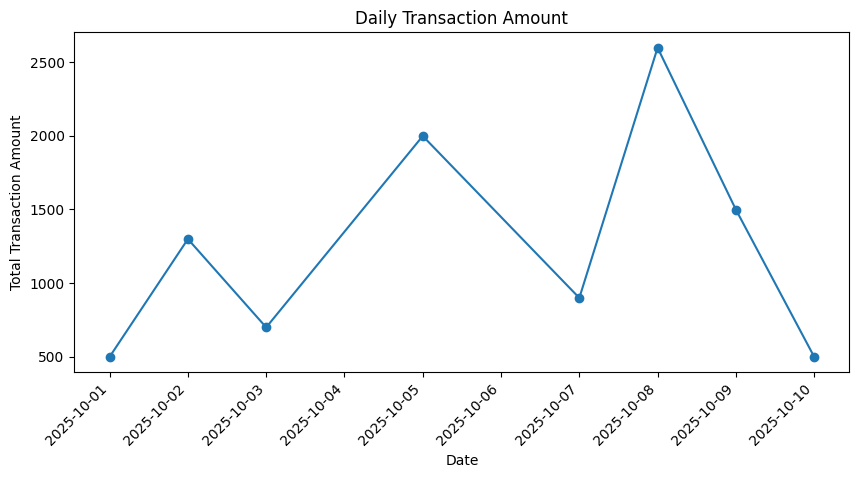

In [35]:
daily_transactions = transactions_df.groupby('date')['amount'].sum()
display(daily_transactions)
daily_transactions.plot(kind='line',figsize=(10,5),marker='o')
plt.title("Daily Transaction Amount")
plt.xlabel("Date")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=45)
plt.show()

In [36]:
print("First Transaction Date:",transactions_df['date'].min())
print("Last Transaction Date:",transactions_df['date'].max())
print("Total Days:",transactions_df['date'].nunique())

First Transaction Date: 2025-10-01 00:00:00
Last Transaction Date: 2025-10-10 00:00:00
Total Days: 8


### 7. Categorical Data Encoding

Categorical data contains values in the form of labels or categories.

Machine Learning algorithms generally require numerical data. Therefore, categorical data is converted into numerical values using encoding techniques.

Common encoding techniques:
- Label Encoding
- One-Hot Encoding

In this project, we demonstrate both techniques using customer and transaction data.

In [37]:
categorical_columns = customers_df.select_dtypes(include='object').columns
print("Categorical Columns:",list(categorical_columns))

Categorical Columns: ['name', 'gender', 'city']


In [61]:
payment_encoded = pd.get_dummies(transactions_df,columns=['payment_mode'],dtype=int)
display(payment_encoded.head())

,transaction_id,customer_id,product_id,amount,date,year,month,day,day_name,payment_mode_Cash,payment_mode_Credit Card,payment_mode_Debit Card,payment_mode_UPI
0,T001,101,P001,499,2025-10-01,2025,10,1,Wednesday,0,0,0,1
1,T002,103,P003,1299,2025-10-02,2025,10,2,Thursday,0,1,0,0
2,T003,104,P002,699,2025-10-03,2025,10,3,Friday,0,0,1,0
3,T004,105,P005,1999,2025-10-05,2025,10,5,Sunday,0,0,0,1
4,T005,107,P004,899,2025-10-07,2025,10,7,Tuesday,1,0,0,0


In [38]:
from sklearn.preprocessing import LabelEncoder
encoding_df = customers_df.copy()
label_encoder = LabelEncoder()
encoding_df['gender_encoded'] = label_encoder.fit_transform(encoding_df['gender'])
display(encoding_df[['gender','gender_encoded']])

,gender,gender_encoded
0,Male,1
1,Female,0
2,Male,1
3,Female,0
4,Male,1
5,Female,0
6,Male,1
7,Female,0


In [39]:
from sklearn.preprocessing import LabelEncoder
encoding_df = customers_df.copy()
label_encoder = LabelEncoder()
encoding_df['gender_encoded'] = label_encoder.fit_transform(encoding_df['gender'])
display(encoding_df[['gender','gender_encoded']])

,gender,gender_encoded
0,Male,1
1,Female,0
2,Male,1
3,Female,0
4,Male,1
5,Female,0
6,Male,1
7,Female,0


In [40]:
products_encoded = pd.get_dummies(products_df,columns=['category'],dtype=int)
display(products_encoded)

,product_id,product_name,price,stock,category_Audio,category_Computer,category_Electronics,category_Mobile Accessories,category_Wearable
0,P001,Earphones,499,50,0,0,1,0,0
1,P002,Bluetooth Speaker,699,40,1,0,0,0,0
2,P003,Smart Watch,1299,25,0,0,0,0,1
3,P004,Keyboard,899,60,0,1,0,0,0
4,P005,Headphones,1999,30,1,0,0,0,0
5,P006,Power Bank,2599,20,0,0,0,1,0


### 8. Feature Scaling

Feature Scaling is a data preprocessing technique used to bring numerical features into a similar range.

It is useful because different numerical columns may have different scales.

Common Feature Scaling techniques:
- Min-Max Scaling
- Standardization (Z-Score Scaling)

In this project, we demonstrate both techniques using numerical columns from the merged dataset.

In [41]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
scaling_df = merged_df[['age','income','amount','price','stock']].copy()
display(scaling_df.head())

,age,income,amount,price,stock
0,24,45000,499,499,50
1,27,48000,1299,1299,25
2,35,60000,699,699,40
3,40,75000,1999,1999,30
4,29,50000,899,899,60


In [42]:
minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(scaling_df)
minmax_df = pd.DataFrame(minmax_scaled,columns=scaling_df.columns)
display(minmax_df)

,age,income,amount,price,stock
0,0.111111,0.090909,0.000000,0.000000,0.750
1,0.277778,0.181818,0.380952,0.380952,0.125
2,0.722222,0.545455,0.095238,0.095238,0.500
3,1.000000,1.000000,0.714286,0.714286,0.250
4,0.388889,0.242424,0.190476,0.190476,1.000
5,0.611111,0.484848,1.000000,1.000000,0.000
6,0.444444,0.393939,0.476190,0.380952,0.125
7,0.000000,0.000000,0.000000,0.000000,0.750


In [43]:
standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(scaling_df)
standard_df = pd.DataFrame(standard_scaled,columns=scaling_df.columns)
display(standard_df)

,age,income,amount,price,stock
0,-1.086429,-0.929578,-1.060660,-1.033738,0.912871
1,-0.543214,-0.623963,0.070711,0.106938,-0.912871
2,0.905357,0.598495,-0.777817,-0.748569,0.182574
3,1.810715,2.126569,1.060660,1.105031,-0.547723
4,-0.181071,-0.420220,-0.494975,-0.463400,1.643168
5,0.543214,0.394752,1.909188,1.960538,-1.278019
6,0.000000,0.089138,0.353553,0.106938,-0.912871
7,-1.448572,-1.235193,-1.060660,-1.033738,0.912871


In [44]:
print("Original Data:")
display(scaling_df.head())
print("Min-Max Scaled Data:")
display(minmax_df.head())
print("Standardized Data:")
display(standard_df.head())

Original Data:


,age,income,amount,price,stock
0,24,45000,499,499,50
1,27,48000,1299,1299,25
2,35,60000,699,699,40
3,40,75000,1999,1999,30
4,29,50000,899,899,60


Min-Max Scaled Data:


,age,income,amount,price,stock
0,0.111111,0.090909,0.000000,0.000000,0.750
1,0.277778,0.181818,0.380952,0.380952,0.125
2,0.722222,0.545455,0.095238,0.095238,0.500
3,1.000000,1.000000,0.714286,0.714286,0.250
4,0.388889,0.242424,0.190476,0.190476,1.000


Standardized Data:


,age,income,amount,price,stock
0,-1.086429,-0.929578,-1.060660,-1.033738,0.912871
1,-0.543214,-0.623963,0.070711,0.106938,-0.912871
2,0.905357,0.598495,-0.777817,-0.748569,0.182574
3,1.810715,2.126569,1.060660,1.105031,-0.547723
4,-0.181071,-0.420220,-0.494975,-0.463400,1.643168


### 9. Feature Construction and Data Transformation

Feature Construction is the process of creating new features from existing columns to get more useful information.

Data Transformation is the process of changing data into a suitable format for analysis.

In this project, we create new features from transaction and customer data.

Examples:
- Total Amount: Transaction amount multiplied by quantity.
- Age Group: Categorize customers based on their age.
- Income Category: Categorize customers based on their income.
- Log Transformation: Reduce the effect of skewness in numerical data.

In [45]:
feature_df = merged_df.copy()
feature_df['total_purchase_value'] = feature_df['amount']
display(feature_df[['transaction_id','amount','total_purchase_value']].head())

,transaction_id,amount,total_purchase_value
0,T001,499,499
1,T002,1299,1299
2,T003,699,699
3,T004,1999,1999
4,T005,899,899


In [46]:
feature_df['age_group'] = pd.cut(feature_df['age'],bins=[0,25,35,100],labels=['Young','Adult','Senior'])
display(feature_df[['name','age','age_group']])

,name,age,age_group
0,Aarav,24,Young
1,Kabir,27,Adult
2,Meera,35,Adult
3,Vivaan,40,Senior
4,Aryan,29,Adult
5,Isha,33,Adult
6,Diya,30,Adult
7,Riya,22,Young


In [47]:
feature_df['income_category'] = pd.cut(feature_df['income'],bins=[0,45000,60000,100000],labels=['Low','Medium','High'],include_lowest=True)
display(feature_df[['name','income','income_category']])

,name,income,income_category
0,Aarav,45000,Low
1,Kabir,48000,Medium
2,Meera,60000,Medium
3,Vivaan,75000,High
4,Aryan,50000,Medium
5,Isha,58000,Medium
6,Diya,55000,Medium
7,Riya,42000,Low


In [48]:
feature_df['log_amount'] = np.log1p(feature_df['amount'])
display(feature_df[['amount','log_amount']])

,amount,log_amount
0,499,6.214608
1,1299,7.170120
2,699,6.551080
3,1999,7.600902
4,899,6.802395
5,2599,7.863267
6,1499,7.313220
7,499,6.214608


In [49]:
print("Original Amount Skewness:",feature_df['amount'].skew())
print("Log Transformed Amount Skewness:",feature_df['log_amount'].skew())

Original Amount Skewness: 0.8135685281523616
Log Transformed Amount Skewness: 0.0813141930663583


In [50]:
display(feature_df[['name','age','age_group','income','income_category','amount','total_purchase_value','log_amount']])

,name,age,age_group,income,income_category,amount,total_purchase_value,log_amount
0,Aarav,24,Young,45000,Low,499,499,6.214608
1,Kabir,27,Adult,48000,Medium,1299,1299,7.170120
2,Meera,35,Adult,60000,Medium,699,699,6.551080
3,Vivaan,40,Senior,75000,High,1999,1999,7.600902
4,Aryan,29,Adult,50000,Medium,899,899,6.802395
5,Isha,33,Adult,58000,Medium,2599,2599,7.863267
6,Diya,30,Adult,55000,Medium,1499,1499,7.313220
7,Riya,22,Young,42000,Low,499,499,6.214608


### 10. Final Output and Project Summary

In this step, we review the complete data preprocessing process and prepare the final output.

The following operations were performed:
- Data Collection and Import
- Data Understanding
- Exploratory Data Analysis (EDA)
- Missing Data Handling
- Outlier Detection and Handling
- Date-Time Handling
- Categorical Data Encoding
- Feature Scaling
- Feature Construction
- Data Transformation

The final processed dataset is prepared for further analysis.

In [51]:
final_df = feature_df.copy()
display(final_df.head())

,transaction_id,customer_id,product_id,amount,payment_mode,date,name,age,gender,city,income,product_name,category,price,stock,total_purchase_value,age_group,income_category,log_amount
0,T001,101,P001,499,UPI,2025-10-01,Aarav,24,Male,Mumbai,45000,Earphones,Electronics,499,50,499,Young,Low,6.214608
1,T002,103,P003,1299,Credit Card,2025-10-02,Kabir,27,Male,Bangalore,48000,Smart Watch,Wearable,1299,25,1299,Adult,Medium,7.170120
2,T003,104,P002,699,Debit Card,2025-10-03,Meera,35,Female,Ahmedabad,60000,Bluetooth Speaker,Audio,699,40,699,Adult,Medium,6.551080
3,T004,105,P005,1999,UPI,2025-10-05,Vivaan,40,Male,Pune,75000,Headphones,Audio,1999,30,1999,Senior,High,7.600902
4,T005,107,P004,899,Cash,2025-10-07,Aryan,29,Male,Kolkata,50000,Keyboard,Computer,899,60,899,Adult,Medium,6.802395


In [52]:
print("Final Dataset Shape:",final_df.shape)
print("Total Rows:",final_df.shape[0])
print("Total Columns:",final_df.shape[1])

Final Dataset Shape: (8, 19)
Total Rows: 8
Total Columns: 19


In [53]:
print("Missing Values:")
print(final_df.isnull().sum())

Missing Values:
transaction_id          0
customer_id             0
product_id              0
amount                  0
payment_mode            0
date                    0
name                    0
age                     0
gender                  0
city                    0
income                  0
product_name            0
category                0
price                   0
stock                   0
total_purchase_value    0
age_group               0
income_category         0
log_amount              0
dtype: int64


In [54]:
print("Total Duplicate Rows:",final_df.duplicated().sum())

Total Duplicate Rows: 0


In [55]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   transaction_id        8 non-null      object  
 1   customer_id           8 non-null      int64   
 2   product_id            8 non-null      object  
 3   amount                8 non-null      int64   
 4   payment_mode          8 non-null      object  
 5   date                  8 non-null      object  
 6   name                  8 non-null      object  
 7   age                   8 non-null      int64   
 8   gender                8 non-null      object  
 9   city                  8 non-null      object  
 10  income                8 non-null      int64   
 11  product_name          8 non-null      object  
 12  category              8 non-null      object  
 13  price                 8 non-null      int64   
 14  stock                 8 non-null      int64   
 15  total_purc

In [57]:
import os
os.makedirs('../Output',exist_ok=True)
print("Output folder created successfully!")

Output folder created successfully!


In [58]:
final_df.to_csv('../Output/final_customer_purchase_data.csv',index=False)
print("Final Dataset Saved Successfully!")

Final Dataset Saved Successfully!
